# Residual Plot
- residuals are used to evaluate regression problems
- x-axis - predicted values
- y-axis - residuals
- ideal: random scatter
- curved/u-shaped - nonlinearity
- funnel - heteroscedasticity
- clustered points and outliers

Training: 10661 rows | 70 unique players
Validation: 2169 rows | 15 unique players
Testing: 2170 rows | 15 unique players


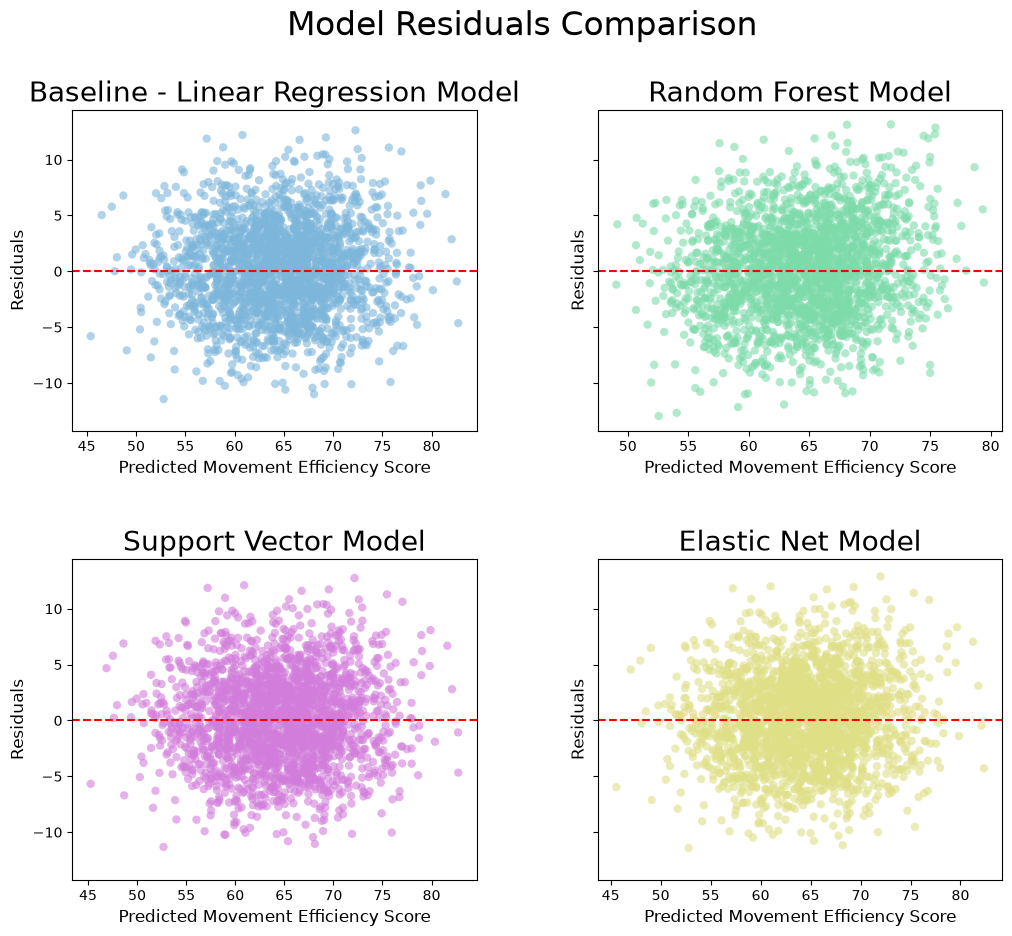

In [4]:
import joblib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
#need to access the testing fold so import from the data_splitter Python script to load and split the data
import sys
import os
sys.path.append(os.path.abspath(os.path.join('..'))) #used to move to the parent folder
from src.data_splitter import load_data, split

#load dataset and variables
df, X, y = load_data()

#split data by groups
X_train, X_val, X_test, y_train, y_val, y_test = split(df, X, y)

#load the models using joblib
baseline = joblib.load('baseline.joblib')
random_forest = joblib.load('random_forest.joblib')
support_vector = joblib.load('support_vector.joblib')
elastic_net = joblib.load('elastic_net.joblib')

#showing 2 plots next to each other at a time
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharey=True, gridspec_kw={'hspace': 0.4, 'wspace': 0.3})
ax1, ax2, ax3, ax4 = axes.flatten()

#baseline plot
baseline_y_pred = baseline.predict(X_test)
baseline_res = y_test - baseline_y_pred #calculate residuals (acual value - predicted value)

ax1.set_title('Baseline - Linear Regression Model', fontsize=20)
ax1.scatter(baseline_y_pred, baseline_res, alpha=.6, c='#7db6db', edgecolors='none')
ax1.axhline(y=0, color='r', linestyle='--')
ax1.set_xlabel('Predicted Movement Efficiency Score', fontsize=12)
ax1.set_ylabel('Residuals', fontsize=12)

#random forest plot
rf_y_pred = random_forest.predict(X_test)
rf_res = y_test - rf_y_pred #calculate residuals (acual value - predicted value)

ax2.set_title('Random Forest Model', fontsize=20)
ax2.scatter(rf_y_pred, rf_res, alpha=.6, c='#7ddbaa', edgecolors='none')
ax2.axhline(y=0, color='r', linestyle='--')
ax2.set_xlabel('Predicted Movement Efficiency Score', fontsize=12)
ax2.set_ylabel('Residuals', fontsize=12)

#support vector plot
sv_y_pred = support_vector.predict(X_test)
sv_res = y_test - sv_y_pred #calculate residuals (acual value - predicted value)

ax3.set_title('Support Vector Model', fontsize=20)
ax3.scatter(sv_y_pred, sv_res, alpha=.6, c='#d27ddb', edgecolors='none')
ax3.axhline(y=0, color='r', linestyle='--')
ax3.set_xlabel('Predicted Movement Efficiency Score', fontsize=12)
ax3.set_ylabel('Residuals', fontsize=12)

#elastic net plot
en_y_pred = elastic_net.predict(X_test)
en_res = y_test - en_y_pred #calculate residuals (acual value - predicted value)

ax4.set_title('Elastic Net Model', fontsize=20)
ax4.scatter(en_y_pred, en_res, alpha=.6, c='#dfdf86', edgecolors='none')
ax4.axhline(y=0, color='r', linestyle='--')
ax4.set_xlabel('Predicted Movement Efficiency Score', fontsize=12)
ax4.set_ylabel('Residuals', fontsize=12)

plt.suptitle('Model Residuals Comparison', fontsize=24)
plt.savefig('../reports/model_residuals_grid.png', dpi=300, bbox_inches='tight')
plt.show()

# Residual Analysis
- independence - may be violated since players are repeated and the errors may not be independent
## Baseline - Linear Regression
- linearity - centered evenly around y=0 line
- heteroscedasticity (constant variance) - no cone/funnel shape
- few outliers but won't dramatically affect model
- most tightly clustered points of the graphs
## Random Forest
- biased toward the upper right - slight cone shape, so likely that variance is not constant
- most outliers of all models
## Support Vector 
- plot looks basically identical with linear regression plot and elastic net plot
## Elastic Net
- plot looks basically identical with linear regression plot and support vector plot

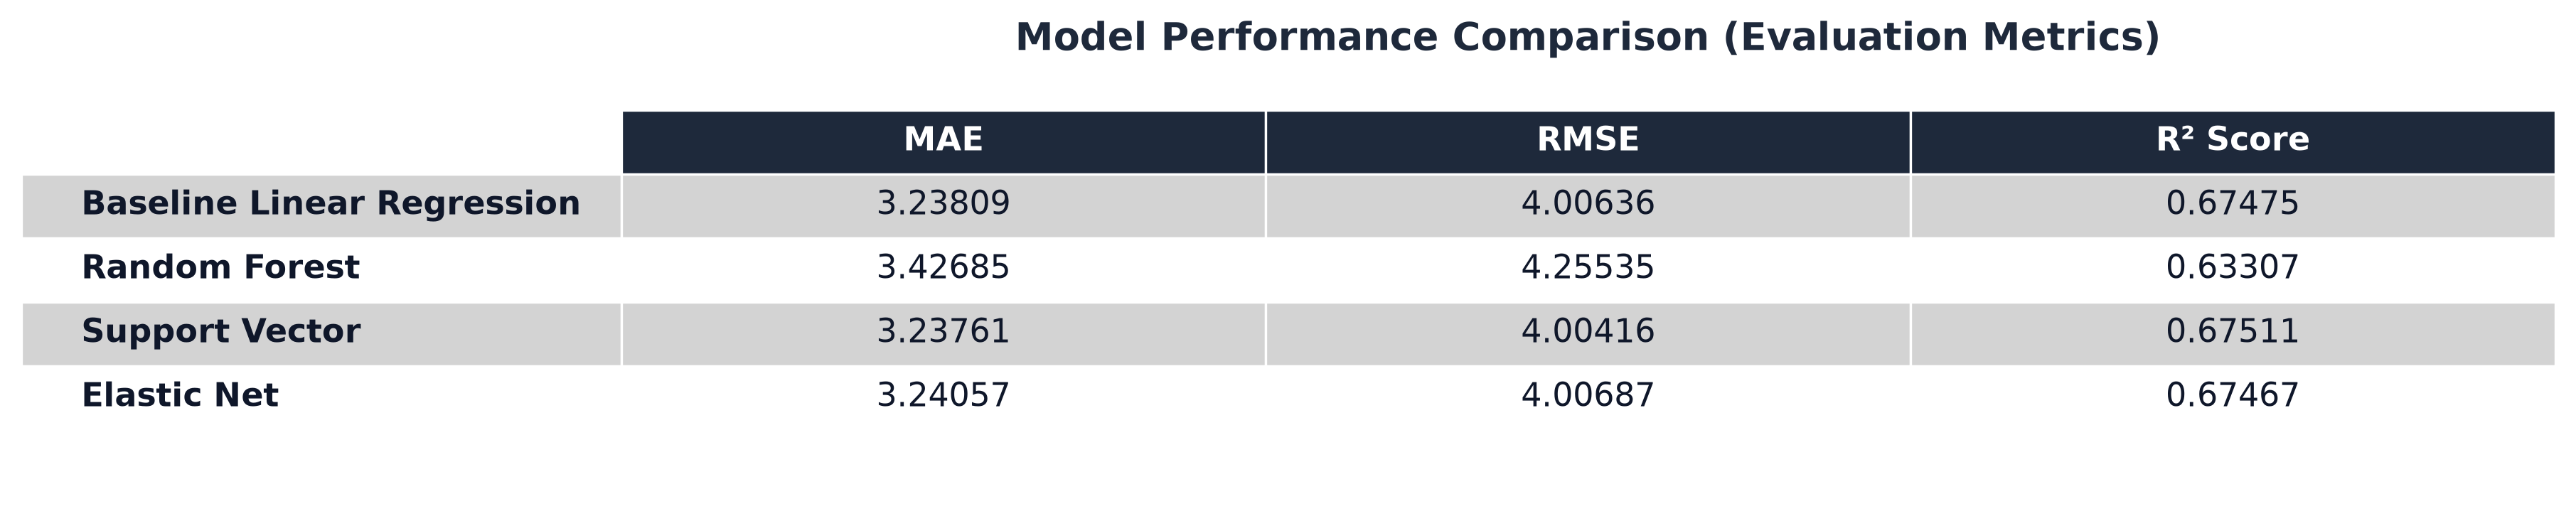

In [5]:
#comparison chart for the models
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

#baseline evaluation
baseline_val_mae = mean_absolute_error(y_test, baseline_y_pred)
baseline_val_rmse = root_mean_squared_error(y_test, baseline_y_pred)
baseline_val_r2 = r2_score(y_test, baseline_y_pred)

#random forest evaluation
rf_val_mae = mean_absolute_error(y_test, rf_y_pred)
rf_val_rmse = root_mean_squared_error(y_test, rf_y_pred)
rf_val_r2 = r2_score(y_test, rf_y_pred)

#support vector evaluation
sv_val_mae = mean_absolute_error(y_test, sv_y_pred)
sv_val_rmse = root_mean_squared_error(y_test, sv_y_pred)
sv_val_r2 = r2_score(y_test, sv_y_pred)

#elastic net evaluation
en_val_mae = mean_absolute_error(y_test, en_y_pred)
en_val_rmse = root_mean_squared_error(y_test, en_y_pred)
en_val_r2 = r2_score(y_test, en_y_pred)

#summary dictionary
results_data = {
    "Model": ["Baseline Linear Regression", "Random Forest", "Support Vector", "Elastic Net"],
    "MAE": [baseline_val_mae, rf_val_mae, sv_val_mae, en_val_mae],
    "RMSE": [baseline_val_rmse, rf_val_rmse, sv_val_rmse, en_val_rmse],
    "R² Score": [baseline_val_r2, rf_val_r2, sv_val_r2, en_val_r2]
}

results_df = pd.DataFrame(results_data)
results_df = results_df.set_index('Model')

#creates an image version of the chart and saves in the report folder
fig, ax = plt.subplots(figsize=(9, 2.8), dpi=300)
ax.axis('off')
ax.axis('tight')

ax.text(0.5, 1.0, 'Model Performance Comparison (Evaluation Metrics)', fontsize=13, fontweight='bold', color='#1e293b', ha='center', va='center', transform=ax.transAxes)

#table for image file
df_to_plot = results_df.round(5)
table = ax.table(
    cellText=df_to_plot.values,
    colLabels=df_to_plot.columns,
    rowLabels=df_to_plot.index,
    loc='center',
    cellLoc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.3, 1.8) 

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#ffffff')
    cell.set_linewidth(0.8)
    
    if row == 0:
        #header
        cell.set_facecolor('#1e293b')
        cell.set_text_props(weight='bold', color='white')
    elif col == -1:
        #model names
        cell.set_text_props(weight='bold', color='#0f172a', ha='left')
        if row % 2 == 1:
            cell.set_facecolor('#D3D3D3')
        else:
            cell.set_facecolor('#ffffff')
    else:
        #data cells with zebra stripes
        if row % 2 == 1:
            cell.set_facecolor('#D3D3D3')
        else:
            cell.set_facecolor('#ffffff')
        cell.set_text_props(color='#0f172a')

plt.savefig('../reports/model_comparison_table.png', dpi=300, bbox_inches='tight')
plt.show()

# Error Analysis
- Support Vector performs slightly better than Linear Regression but the improvement is visible in the 3rd decimal place so not much better
- Elastic Net does slightly worse than Support Vector but not significant since in 3rd decimal place
    - does worse than linear regression in MAE and RMSE (3rd decimal place), does better in R² (4th decimal place) so not significant
- Random Forest performs substantially worse than the other 2 models in all evaluation metrics
- since linear regression and support vector with linear kernal did basically the same, the data likely has a linear relationship
- random forest is likely doing worse because the data has a linear relationship

# Conclusion
## Best Model
- best model based on evaluation metrics is technically Support Vector but the increase in performance is basically non-negligible because it's visible at the 3rd decimal point
      - explains why Linear Regression's and Support Vector's residual plots look identical
- Elastic Net also has basically the same evaluation metrics which explains the similarity in Linear Regression's residual plot (and Support Vector's)
- worst model: random forest, likely due to a non-linear relationship in the data
## Limitations
- samples may be dependent because players are repeated multiple times
- using 23 input features, so some could be noise that is distracting the model
- model may be experiencing multicollinearity because some input features are likely related (ex: elbow_angular_acceleration_deg_s2 and wrist_angular_acceleration_deg_s2)
## Next Steps
- determine which input variables are noise and can be removed
- test other linear models and try to do significantly better than the baseline linear regression